In [12]:
import pandas as pd
df = pd.read_csv("solar_weather.csv")
df.head()

/tmp/ipython-input-419/4073049678.py:2: DtypeWarning: Columns (1,2,3,4,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("solar_weather.csv")


,Time,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light
0,01-01-2017 00:00,0,0,1.6,0,100,450
1,01-01-2017 00:15,0,0,1.6,0,100,450
2,01-01-2017 00:30,0,0,1.6,0,100,450
3,01-01-2017 00:45,0,0,1.6,0,100,450
4,01-01-2017 01:00,0,0,1.7,0,100,450


In [13]:
df.columns = df.columns.str.strip()
for col in df.columns:
    if col != 'Time':
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.dtypes)

Time                           object
Energy Captured[Wh]           float64
Sun Light Intensity (W/m2)    float64
Temperature                   float64
1 Hour Rain Fall              float64
Cloud Coverage                float64
Length of Day_Light           float64
dtype: object


Task 1-Exploratory Data Analysis

In [14]:
df.dtypes

,0
Time,object
Energy Captured[Wh],float64
Sun Light Intensity (W/m2),float64
Temperature,float64
1 Hour Rain Fall,float64
Cloud Coverage,float64
Length of Day_Light,float64


In [15]:
# Checking info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196777 entries, 0 to 196776
Data columns (total 7 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Time                        196777 non-null  object 
 1   Energy Captured[Wh]         196773 non-null  float64
 2   Sun Light Intensity (W/m2)  196770 non-null  float64
 3   Temperature                 196771 non-null  float64
 4   1 Hour Rain Fall            196773 non-null  float64
 5   Cloud Coverage              196764 non-null  float64
 6   Length of Day_Light         196772 non-null  float64
dtypes: float64(6), object(1)
memory usage: 10.5+ MB


In [16]:
# Statistical summary
df.describe()

,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light
count,196773.000000,196770.000000,196771.000000,196773.000000,196764.000000,196772.000000
mean,573.011262,32.598451,9.790703,0.066036,65.970798,748.650189
std,1044.832388,52.175402,7.995447,0.278915,36.637595,194.867878
min,-54.000000,0.000000,-16.600000,0.000000,-250.000000,450.000000
25%,0.000000,0.000000,3.600000,0.000000,34.000000,570.000000
50%,0.000000,1.600000,9.300000,0.000000,82.000000,765.000000
75%,577.000000,46.800000,15.700000,0.000000,100.000000,930.000000
max,5020.000000,270.000000,35.800000,8.090000,101.000000,1020.000000


In [17]:
# Column names
df.columns

Index(['Time', 'Energy Captured[Wh]', 'Sun Light Intensity (W/m2)',
       'Temperature', '1 Hour Rain Fall', 'Cloud Coverage',
       'Length of Day_Light'],
      dtype='object')

In [18]:
# Shape of the dataset
df.shape

(196777, 7)

In [19]:
# Checking for missing values
df.isnull().sum()

,0
Time,0
Energy Captured[Wh],4
Sun Light Intensity (W/m2),7
Temperature,6
1 Hour Rain Fall,4
Cloud Coverage,13
Length of Day_Light,5


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196777 entries, 0 to 196776
Data columns (total 7 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Time                        196777 non-null  object 
 1   Energy Captured[Wh]         196773 non-null  float64
 2   Sun Light Intensity (W/m2)  196770 non-null  float64
 3   Temperature                 196771 non-null  float64
 4   1 Hour Rain Fall            196773 non-null  float64
 5   Cloud Coverage              196764 non-null  float64
 6   Length of Day_Light         196772 non-null  float64
dtypes: float64(6), object(1)
memory usage: 10.5+ MB


Descriptive statistics (Mean, Median, Mode, Standard Deviation)


In [21]:
mean_values=df.mean(numeric_only=True)
print("Mean:\n", mean_values )


Mean:
 Energy Captured[Wh]           573.011262
Sun Light Intensity (W/m2)     32.598451
Temperature                     9.790703
1 Hour Rain Fall                0.066036
Cloud Coverage                 65.970798
Length of Day_Light           748.650189
dtype: float64


In [22]:
median_values = df.median(numeric_only=True)
print("Median:\n", median_values)


Median:
 Energy Captured[Wh]             0.0
Sun Light Intensity (W/m2)      1.6
Temperature                     9.3
1 Hour Rain Fall                0.0
Cloud Coverage                 82.0
Length of Day_Light           765.0
dtype: float64


In [23]:
std_values = df.std(numeric_only=True)
print("Standard Deviation:\n", std_values)

Standard Deviation:
 Energy Captured[Wh]           1044.832388
Sun Light Intensity (W/m2)      52.175402
Temperature                      7.995447
1 Hour Rain Fall                 0.278915
Cloud Coverage                  36.637595
Length of Day_Light            194.867878
dtype: float64


In [24]:
df=df.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 196738 entries, 0 to 196776
Data columns (total 7 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Time                        196738 non-null  object 
 1   Energy Captured[Wh]         196738 non-null  float64
 2   Sun Light Intensity (W/m2)  196738 non-null  float64
 3   Temperature                 196738 non-null  float64
 4   1 Hour Rain Fall            196738 non-null  float64
 5   Cloud Coverage              196738 non-null  float64
 6   Length of Day_Light         196738 non-null  float64
dtypes: float64(6), object(1)
memory usage: 12.0+ MB


Correlation heatmaps to identify relationships between variables

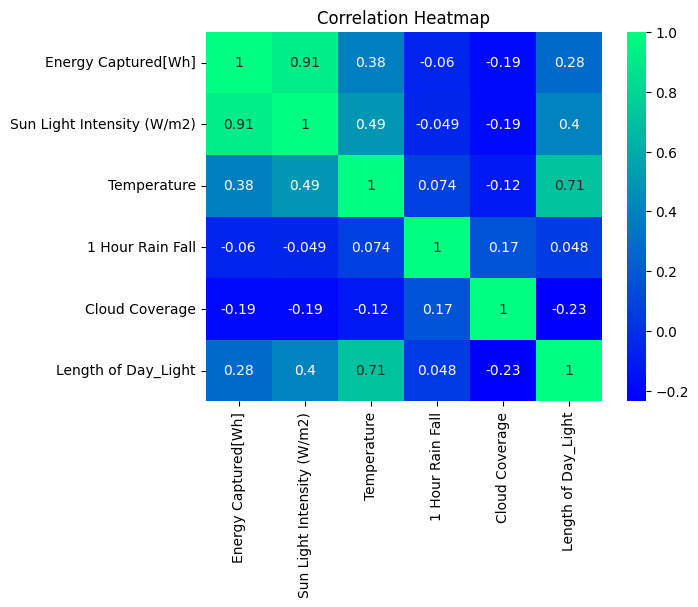

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
correlation = df.corr(numeric_only=True)
plt.figure
sns.heatmap(correlation, annot=True, cmap="winter")
plt.title("Correlation Heatmap")
plt.show()

Frequency Distribution Charts of the variables

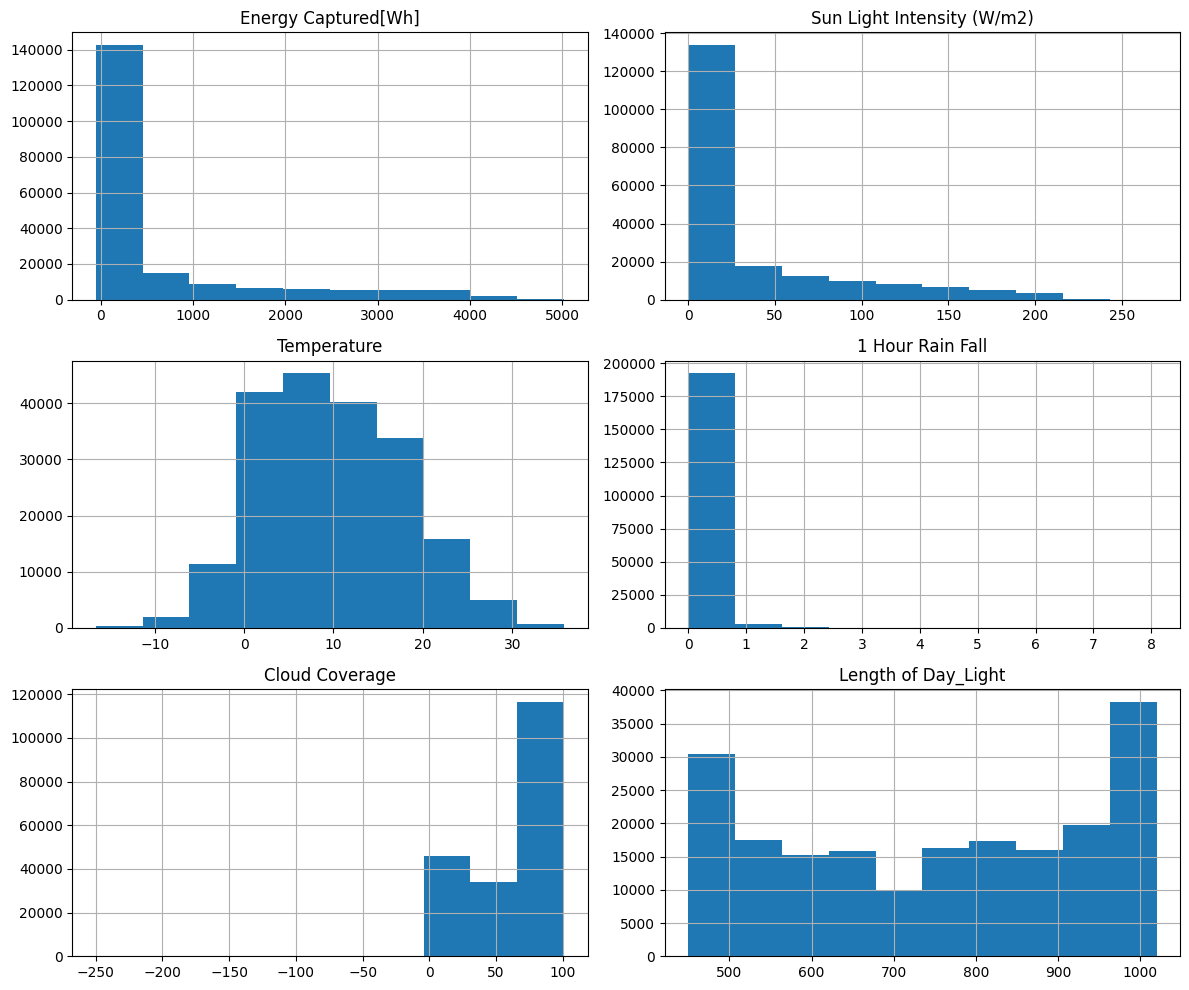

In [26]:
df.hist(figsize=(12,10))
plt.tight_layout()
plt.show()

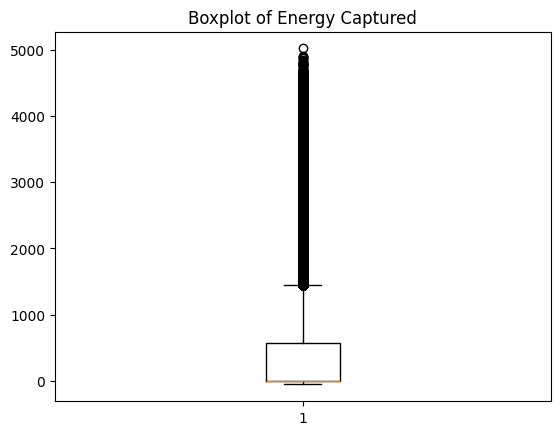

In [27]:
plt.boxplot(df['Energy Captured[Wh]'])
plt.title("Boxplot of Energy Captured")
plt.show()